# Identify and cluster spatial

In [17]:
%%capture

import pandas as pd
import numpy as np
from setfit import SetFitModel
from sentence_transformers import SentenceTransformer
import umap
import csv
from pathlib import Path
import hdbscan
import json

In [2]:
chats = pd.concat([
    # Sharechat
    pd.read_parquet(
        'interim/sharechat.en.len140.parquet'
    ).filter([
        'url', 'plain_text'
    ]).rename(columns={
        'url': 'id',
        'plain_text': 'prompt',
    }),

    # Wildchat
    pd.read_parquet(
        'interim/wildchat.en.len140.parquet'
    ).filter([
        'conversation_hash', 'first_prompt'
    ]).rename(columns={
        'conversation_hash': 'id',
        'first_prompt': 'prompt'
    })
]).drop_duplicates(subset=['prompt'])

/Users/ilya/miniconda3/lib/python3.11/site-packages/pandas/core/frame.py:717: DeprecationWarning: Passing a BlockManager to DataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
/Users/ilya/miniconda3/lib/python3.11/site-packages/pyarrow/pandas_compat.py:722: DeprecationWarning: DatetimeTZBlock is deprecated and will be removed in a future version. Use public APIs instead.
  klass=_int.DatetimeTZBlock,
/Users/ilya/miniconda3/lib/python3.11/site-packages/pandas/core/frame.py:717: DeprecationWarning: Passing a BlockManager to DataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [3]:
spatial_classifier = SetFitModel.from_pretrained('ilyankou/spatial-classifier')

/Users/ilya/miniconda3/lib/python3.11/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.3.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
%%time
# takes ca 2min for 150k samples
preds = spatial_classifier.predict( chats.prompt.tolist() )

CPU times: user 44.8 s, sys: 9.01 s, total: 53.8 s
Wall time: 2min 37s


In [5]:
chats['is_spatial'] = preds

In [6]:
chats.is_spatial.value_counts()

is_spatial
0    164357
1      3878
Name: count, dtype: int64

In [9]:
chats.query('is_spatial == 1').to_parquet('interim/spatial.len140.parquet')

## Manually assess our classifier

- Big question: Can we use our classifier that we built for the Bing queries to identify spatial queries in chatgpt and the likes?
- Let's look at a random sample of 100 positives and 100 negatives and build a confusion matrix

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

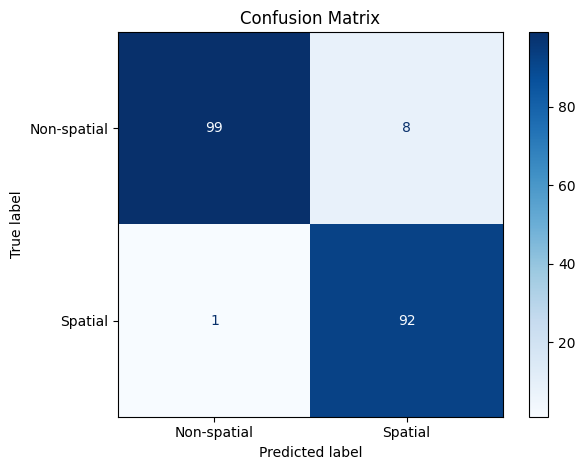

In [12]:
manual_eval = pd.read_excel('interim/spatial_classifier_manual_eval.xlsx')
#manual_eval.filter(['is_spatial', 'human_check'])

cm = confusion_matrix(manual_eval['human_check'], manual_eval['is_spatial'])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-spatial', 'Spatial'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Cluster spatial only

- Use the same UMAP + HDBSCAN method as MS MARCO for more apples-to-apples comparison
- Same grid search to identify best results

In [12]:
spatial = pd.read_parquet('interim/spatial.len140.parquet')
spatial

/Users/ilya/miniconda3/lib/python3.11/site-packages/pandas/core/frame.py:717: DeprecationWarning: Passing a BlockManager to DataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


,id,prompt,is_spatial
1348,https://chatgpt.com/share/67e2dbc9-98e0-8003-8...,"OLÁ BOA TARDE,EU <REDACTED> EXISTEM VACINAS CO...",1
1508,https://chatgpt.com/share/6740d6db-5300-8001-b...,will you help me pick out a boat for 6 people ...,1
4490,https://chatgpt.com/share/676a107f-bd00-8008-9...,Where is taqqiyah in the <REDACTED>,1
6191,https://chatgpt.com/share/68030a05-c504-800a-a...,Ab dikhao,1
13403,https://chatgpt.com/share/67d6f3a4-32f4-8004-8...,Compare andhra pradesh and <REDACTED> in terms...,1
...,...,...,...
57767,49ebd425e924dbd517ce5a4ce6ac31a5,Which country has the most castles,1
57914,03f218c25775fa699f90f0f206f842ec,Are there any states in the USA that aren't co...,1
58620,2119cc26938c02cbe777f1caccc0bcd4,Can you share with me the updated list of firs...,1
58881,5964bc7ab17bf55d8ce7c11473b9a249,write in 2-3 sentences about a group of friend...,1


In [14]:
model = SentenceTransformer("BAAI/bge-small-en-v1.5")

xb_spatial = model.encode(
    spatial.prompt.tolist(),
    batch_size=32,
    normalize_embeddings=True, # cosine‑ready vectors
    show_progress_bar=True
) # --> outputs numpy array shape (len(queries), 384)

Batches:   0%|          | 0/122 [00:00<?, ?it/s]

In [18]:
def log(path='output/umap_hdbscan_runs.csv', config_id=None):
    
    log_path = Path(path)
    write_header = not log_path.exists()
    
    with log_path.open('a', newline='') as f:
        writer = csv.writer(f)
    
        if write_header:
            writer.writerow([
                'config_id',
                'seed',
                'umap_dim',
                'umap_neighbours',
                'umap_min_dist',
                'min_cluster_size',
                'min_samples',
                'dbcv',
                'noise_frac',
                'n_clusters',
                'median_cluster_size',
                'cluster_selection_method'
            ])
    
        writer.writerow([
            config_id,
            seed,
            umap_dim,
            umap_neighbours,
            umap_min_dist,
            min_cluster_size,
            min_samples,
            dbcv,
            noise,
            n_clusters,
            median_size,
            cluster_selection_method
        ])

In [21]:
%%time

seed = 42
cluster_selection_method = 'eom' # by default, let's search the grid with eom

for umap_dim in (5, 10, 15):
    for umap_neighbours in (5, 10, 25):
        for umap_min_dist in (0.0, 0.1):

            for min_cluster_size in (5, 10, 20, 50): # we lowered these, because the dataset is small!
                for min_samples in (None, 5, 10):

                    print('----')
                    print('UMAP n dims:', umap_dim)
                    print('UMAP n neighbours:', umap_neighbours)
                    print('UMAP min dist:', umap_min_dist)
                    print('HDBSCAN min cluster size:', min_cluster_size)
                    print('HDBSCAN min samples:', min_samples)
            
                    reducer = umap.UMAP(
                        n_components=umap_dim,
                        n_neighbors=umap_neighbours,
                        min_dist=umap_min_dist,
                        metric='cosine',
                        n_jobs=1, # -1 for all cores for faster processing but then cannot use random seed...
                        random_state=42
                    )
                    
                    xb_spatial_low = reducer.fit_transform(xb_spatial)
            
                    clusterer = hdbscan.HDBSCAN(
                        min_cluster_size=min_cluster_size,
                        min_samples=min_samples,
                        metric='euclidean',
                        cluster_selection_method=cluster_selection_method,
                        gen_min_span_tree=True
                    )

                    # Fit the model
                    labels = clusterer.fit_predict(xb_spatial_low)

                    # Calculate quality metrics
                    dbcv = clusterer.relative_validity_
                    noise = (labels == -1).mean() # -1 aka invalid/noise
                    
                    n_clusters = len(set(labels)) - (1 if -1 in labels else 0) # exclude noise -1 cluster
                    
                    vc = pd.Series(labels[labels != -1]).value_counts()
                    median_size = vc.median() if len(vc) else 0

                    print(f'DBCV Score: {dbcv}')
                    print(f'% invalid/noise/-1 clusters: {noise}')
                    print(f'# clusters: {n_clusters}')
                    print(f'median cluster size: {median_size}')
                    print('*****************')

                    # Log to the file
                    log()

----
UMAP n dims: 5
UMAP n neighbours: 5
UMAP min dist: 0.0
HDBSCAN min cluster size: 5
HDBSCAN min samples: None
DBCV Score: 0.2480830517423911
% invalid/noise/-1 clusters: 0.23543063434760186
# clusters: 237
median cluster size: 11.0
*****************
----
UMAP n dims: 5
UMAP n neighbours: 5
UMAP min dist: 0.0
HDBSCAN min cluster size: 5
HDBSCAN min samples: 5
DBCV Score: 0.2480830517423911
% invalid/noise/-1 clusters: 0.23543063434760186
# clusters: 237
median cluster size: 11.0
*****************
----
UMAP n dims: 5
UMAP n neighbours: 5
UMAP min dist: 0.0
HDBSCAN min cluster size: 5
HDBSCAN min samples: 10
DBCV Score: 0.21870902143362486
% invalid/noise/-1 clusters: 0.3298091799896854
# clusters: 119
median cluster size: 15.0
*****************
----
UMAP n dims: 5
UMAP n neighbours: 5
UMAP min dist: 0.0
HDBSCAN min cluster size: 10
HDBSCAN min samples: None
DBCV Score: 0.21895460019853555
% invalid/noise/-1 clusters: 0.31304796286745745
# clusters: 106
median cluster size: 17.5
*****

# Check how stable clustering is

- Umap is stochastic
- Let's rerun umap+hdbscan for top config 5 times each to see how dbcv and other qa metrics differ
- We then have more confidence in picking the best params

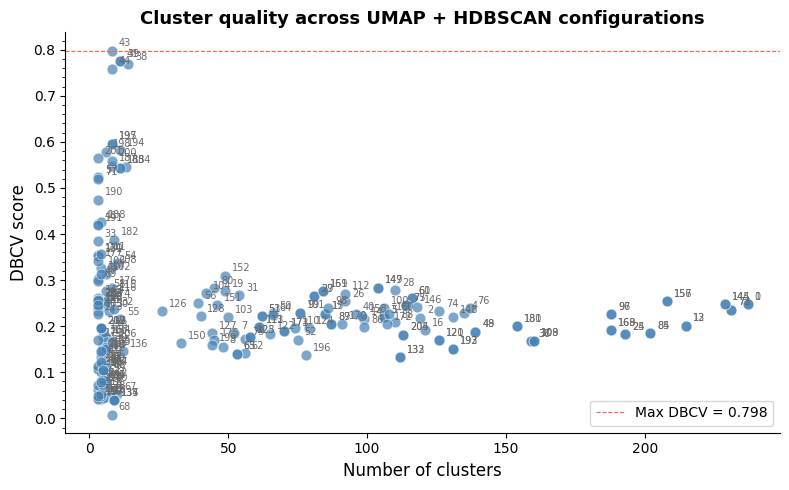

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df = pd.read_csv('output/umap_hdbscan_runs.csv')

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df['n_clusters'],
    df['dbcv'],
    color='steelblue',
    edgecolors='white',
    linewidths=0.5,
    alpha=0.7,
    s=60,
)

ax.set_xlabel('Number of clusters', fontsize=12)
ax.set_ylabel('DBCV score', fontsize=12)
ax.set_title('Cluster quality across UMAP + HDBSCAN configurations', fontsize=13, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=10)
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

ax.axhline(df['dbcv'].max(), color='tomato', linewidth=0.8, linestyle='--', label=f'Max DBCV = {df["dbcv"].max():.3f}')
ax.legend(fontsize=10)

for i, row in df.iterrows():
    ax.annotate(
        i,
        xy=(row['n_clusters'], row['dbcv']),
        xytext=(5, 3),
        textcoords='offset points',
        fontsize=7,
        color='dimgrey',
    )

plt.tight_layout()
plt.savefig('output/umap_hdbscan_scatter.png', dpi=300)
plt.show()

In [61]:
# All top runs produce very few clusters (given our dataset size of almost 4k it's not ideal)
# So our original robustness analysis doesn't quite work here
# Let's manually identify the top performer which has around 50 clusters (in the scatter chart), so config 152.

top_run = pd.read_csv('output/umap_hdbscan_runs.csv').loc[152]
top_run

config_id                        NaN
seed                              42
umap_dim                          15
umap_neighbours                    5
umap_min_dist                    0.0
min_cluster_size                  20
min_samples                     10.0
dbcv                        0.309812
noise_frac                  0.317432
n_clusters                        49
median_cluster_size             35.0
cluster_selection_method         eom
Name: 152, dtype: object

In [68]:
%%time

reducer = umap.UMAP(
    n_components=int(top_run.umap_dim),
    n_neighbors=int(top_run.umap_neighbours),
    min_dist=top_run.umap_min_dist,
    metric='cosine',
    n_jobs=1,
    random_state=42 # get orig seed
)
    
xb_spatial_low = reducer.fit_transform(xb_spatial)

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=int(top_run.min_cluster_size),
    min_samples=int(top_run.min_samples), 
    metric='euclidean',
    cluster_selection_method='eom',
    gen_min_span_tree=True
)

# Get the lables
labels = clusterer.fit_predict(xb_spatial_low)

CPU times: user 9.86 s, sys: 86.5 ms, total: 9.94 s
Wall time: 10.1 s


In [70]:
print( len(labels) )
assert len(set(labels)) == (top_run.n_clusters + 1) # adding -1 for noise cluster

3878


## Manually review clusters

In [71]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.spatial.distance import cdist

In [72]:
def analyze_clusters(queries, labels, embeddings, top_n_words=20, sample_size=10):
    df = pd.DataFrame({'query': queries, 'label': labels})
    unique_labels = sorted(df['label'].unique())

    # class-based tf–idf
    docs_per_class = (
        df.groupby('label')['query']
        .apply(lambda x: ' '.join(x))
        .reset_index()
        .sort_values('label')
        .reset_index(drop=True)
    )

    tfidf_model = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    tfidf_matrix = tfidf_model.fit_transform(docs_per_class['query'])
    words = tfidf_model.get_feature_names_out()

    rows = []

    for i, label in enumerate(unique_labels):
        idx = df.index[df['label'] == label]
        cluster_embeddings = embeddings[idx]
        cluster_queries = df.loc[idx, 'query'].values

        # centroid representative
        centroid = cluster_embeddings.mean(axis=0).reshape(1, -1)
        distances = cdist(centroid, cluster_embeddings, 'cosine')[0]
        rep_query = cluster_queries[distances.argmin()]

        # top tf–idf terms
        row_data = tfidf_matrix.getrow(i).toarray()[0]
        top_idx = row_data.argsort()[-top_n_words:][::-1]
        top_terms = [words[j] for j in top_idx]

        # sample queries
        sample_queries = (
            df.loc[idx, 'query']
            .sample(min(len(idx), sample_size), random_state=42)
            .tolist()
        )

        rows.append({
            'label': label,
            'n_samples': len(idx),
            'representative_query': rep_query,
            'top_terms': top_terms,
            'sample_queries': sample_queries,
        })

    return pd.DataFrame(rows).sort_values('label').reset_index(drop=True)


def clusters_df_to_markdown(clusters_df):
    sections = []

    for _, row in clusters_df.iterrows():
        section = [
            f'## Cluster {row["label"]} ({row["n_samples"]} samples)',
            f'**Representative Query:** `{row["representative_query"]}`',
            f'**Top Terms:** {", ".join(row["top_terms"])}',
            '',
            '**Sample Queries:**',
            '\n'.join(f'- {q}' for q in row['sample_queries']),
            '',
            '---',
        ]
        sections.append('\n'.join(section))

    return '\n'.join(sections)

In [73]:
final_clusters = analyze_clusters(
    spatial.reset_index().prompt,
    labels,
    xb_spatial
)

In [74]:
final_clusters_markdown = clusters_df_to_markdown(final_clusters)

In [75]:
with open('output/cluster_review.md', 'w') as f:
    f.write(final_clusters_markdown)

In [76]:
final_clusters.filter([
    'label', 'n_samples', 'representative_query'
]).to_excel('output/cluster_review.xlsx', index=False)